In [1]:
import os
import pathlib
# import json

import yaml
import numpy as np
import pandas as pd
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import altair as alt
import matplotlib.pyplot as plt
import plotly.express as px

import jax
import jax.random as jr
import jax.numpy as jnp

import torch
from torch.utils.data import Subset, DataLoader

import trapallada.data
import trapallada.model
import trapallada.plot

/home/manu/mambaforge/envs/trap/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
os.environ.get('CUDA_VISIBLE_DEVICES', 'No CUDA'), os.environ.get('XLA_PYTHON_CLIENT_PREALLOCATE', 'No XLA')

('No CUDA', 'No XLA')

In [3]:
import plotly.io as pio
pio.renderers.default = 'notebook'

In [4]:
# input_directory =  pathlib.Path(os.environ['MY_DATA_DIR']) / 'trapallada'
input_directory =  pathlib.Path.home() / 'Sync' / 'research' / 'light curves'
assert input_directory.exists()

The *base* file name for the data

In [5]:
# base_filename = pathlib.Path('original.pt')
base_filename = pathlib.Path('small.pt')
# base_filename = pathlib.Path('very_small.pt')

A custom *torch* `Dataset`. Returned `Tensor`s are *normalized* so that numbers are spread between $-1$ and $1$ (rather than between $0$ and $1$).

**TODO**: use *torch* machinery for normalization purposes?

`Dataset` is loaded: 18,000 gray-scale (i.e., single-channel) images. **They are normalized**.

In [6]:
ds = trapallada.data.ImageDataset(
    input_directory / base_filename.with_stem(base_filename.stem + '_imgs'),
    input_directory / base_filename.with_stem(base_filename.stem + '_labels').with_suffix('.parquet'),
)
ds.imgs.shape

torch.Size([18000, 1, 30, 250])

Size of `x`

In [7]:
ds[0][1].shape

torch.Size([1, 30, 250])

The label, `y` encodes the kind of signal

In [8]:
ds[3][2]

1

Size of every image (to be used below)

In [9]:
input_size = tuple(ds[0][1].shape[1:])
input_size

(30, 250)

# Train-test splitting

The indexes for the split are randomly selected

In [10]:
train_idx, validation_idx = train_test_split(np.arange(len(ds)), test_size=0.2, random_state=42, shuffle=True, stratify=ds.labels)

The actual splitting (`Subset` is a *torch* `Dataset`)

In [11]:
train_ds = Subset(ds, train_idx)
validation_ds = Subset(ds, validation_idx)

A *PyTorch* pseudo-random numbers generator

In [12]:
torch_rng = torch.Generator()
torch_rng.manual_seed(2147483647)

Data loaders are instantiated (same `generator` for both)

In [13]:
# batch_size = 64
batch_size = 32
train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=torch_rng)
validation_dl = DataLoader(validation_ds, batch_size=batch_size, shuffle=False, generator=torch_rng)

# Results

In [14]:
# parameters_filename = pathlib.Path(f'weights_z={dim_z}_epochs={n_epochs}.yaml')
parameters_filename = input_directory / pathlib.Path(f'weights_z=3_epochs=5000.yaml')
assert parameters_filename.exists()

In [15]:
with open(parameters_filename, 'r') as f:
        parameters = yaml.safe_load(f)
parameters

{'loss': {'x_sd': 0.3162277638912201},
 'model': {'dim_z': 3, 'input_size': [30, 250]},
 'training': {'batch_size': 32,
  'learning_rate': 3e-05,
  'n_epochs': 5000,
  'splitting': {'random_state': 42, 'test_size': 0.2}}}

For the sake of readability

In [16]:
dim_z = parameters["model"]["dim_z"]

Loading previous weights

In [17]:
weights_filename = input_directory / pathlib.Path(f'weights_z={dim_z}_epochs={parameters["training"]["n_epochs"]}.eqx')
assert weights_filename.exists()

In [18]:
model = trapallada.model.load_vae(weights_filename, parameters["model"]["input_size"], dim_z)
# encoder

Some reconstructions

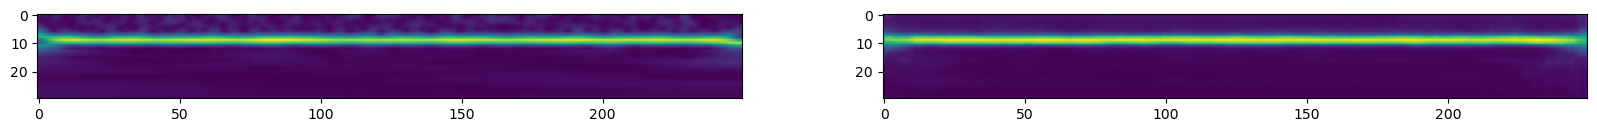

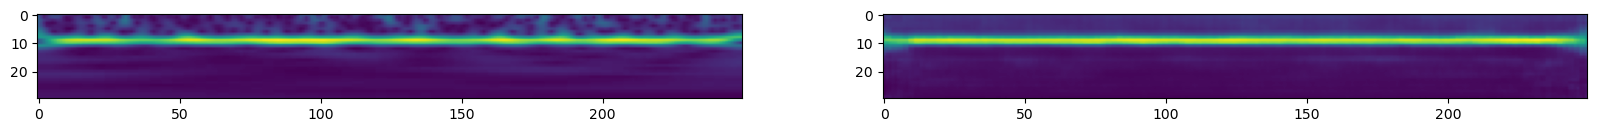

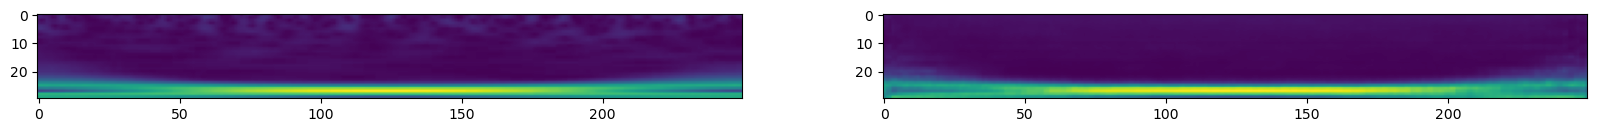

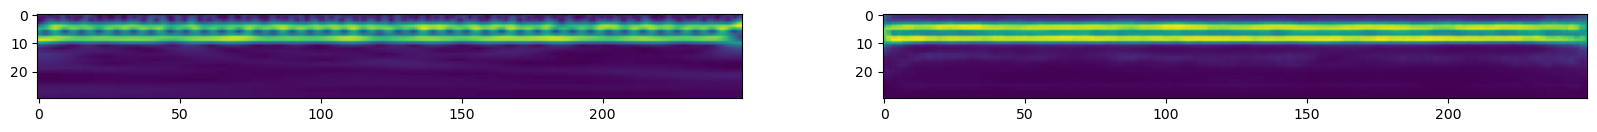

In [19]:
_, x, _ = next(iter(train_dl))
trapallada.plot.img_and_pred(model, x[0], dim_z)
trapallada.plot.img_and_pred(model, x[1], dim_z)
trapallada.plot.img_and_pred(model, x[3], dim_z)
trapallada.plot.img_and_pred(model, x[15], dim_z)

## Latent space

For the sake of convenience

In [20]:
encoder, decoder = model

The `encoder` yields the mean and standard deviation

In [21]:
encoder(x[0].numpy())

Array([-3.33241   ,  1.477854  , -2.3348596 ,  0.01637596,  0.01386305,
        0.01489141], dtype=float32)

The `z` and label of every element in the training set (computed batch-wise due to memory problems). The `i`s returned by the `DataLoader` on the `Subset` are actually those in **original** `DataSet` (since underneath that's what's being used).

In [22]:
z_s, labels, i_s = [], [], []
for i, x, l in train_dl:
    z_s.append(jax.vmap(encoder)(x.numpy()))
    labels.append(l)
    i_s.append(i)

All the values are (vertically) stacked together, and the standard deviation of `z` is dropped

In [23]:
z_s = jnp.vstack(z_s)[:, :dim_z]
labels = torch.concat(labels)
i_s = torch.concat(i_s)
z_s.shape, labels.shape

((14400, 3), torch.Size([14400]))

t-SNE

In [24]:
t_sne_embeddings = TSNE(n_components=2, perplexity=30,random_state=42).fit_transform(z_s)

The names of the *t-SNE* embedgins will be used a couple of times

In [25]:
z_s_names = [f'z_{i}' for i in range(1, 1+dim_z)]
z_s_names

['z_1', 'z_2', 'z_3']

In [26]:
# labels

In [27]:
# ds.df['label'].cat.codes

In [28]:
min(i_s),max(i_s)

(tensor(0), tensor(17999))

In [29]:
ds.df.iloc[i_s]

,label,std,file name
10542,FM,4.0,FM/FM_s4_874.jpg
746,Constant,1.0,Constant/cLC_s1_595.jpg
15613,AM,4.0,AM/AM_s4_646.jpg
16039,AM,1.0,AM/AM_s1_406.jpg
13616,AM,1.0,AM/AM_s1_695.jpg
...,...,...,...
14920,AM,1.0,AM/AM_s1_461.jpg
4436,Constant,5.0,Constant/cLC_s5_450.jpg
7167,FM,4.0,FM/FM_s4_217.jpg
7539,FM,3.0,FM/FM_s3_747.jpg


In [30]:
type(i_s)
# i_s.tolist()

torch.Tensor

In [31]:
latents_df = pd.DataFrame(np.hstack((z_s, t_sne_embeddings)), columns=z_s_names + ['tsne_1', 'tsne_2'], index=i_s.tolist())
latents_df

,z_1,z_2,z_3,tsne_1,tsne_2
10542,0.323751,0.492538,0.203779,-5.197358,-6.588941
746,3.817298,-0.847737,1.831506,-15.569353,-101.571182
15613,3.536286,2.972515,-0.560041,-99.277794,-6.441010
16039,3.029064,3.072926,-1.607801,-84.747406,6.864756
13616,3.744486,3.264333,-0.434687,-101.178413,-5.636007
...,...,...,...,...,...
14920,1.468454,2.892059,-3.393579,-64.493095,17.375805
4436,3.010732,-1.258840,-0.206846,-44.855038,-64.071754
7167,0.210131,2.237611,0.974906,2.211750,28.595856
7539,-1.004200,2.439432,1.220788,-25.549761,74.510468


In [32]:
df = pd.concat((latents_df, ds.df.iloc[i_s]), axis=1)
df

,z_1,z_2,z_3,tsne_1,tsne_2,label,std,file name
10542,0.323751,0.492538,0.203779,-5.197358,-6.588941,FM,4.0,FM/FM_s4_874.jpg
746,3.817298,-0.847737,1.831506,-15.569353,-101.571182,Constant,1.0,Constant/cLC_s1_595.jpg
15613,3.536286,2.972515,-0.560041,-99.277794,-6.441010,AM,4.0,AM/AM_s4_646.jpg
16039,3.029064,3.072926,-1.607801,-84.747406,6.864756,AM,1.0,AM/AM_s1_406.jpg
13616,3.744486,3.264333,-0.434687,-101.178413,-5.636007,AM,1.0,AM/AM_s1_695.jpg
...,...,...,...,...,...,...,...,...
14920,1.468454,2.892059,-3.393579,-64.493095,17.375805,AM,1.0,AM/AM_s1_461.jpg
4436,3.010732,-1.258840,-0.206846,-44.855038,-64.071754,Constant,5.0,Constant/cLC_s5_450.jpg
7167,0.210131,2.237611,0.974906,2.211750,28.595856,FM,4.0,FM/FM_s4_217.jpg
7539,-1.004200,2.439432,1.220788,-25.549761,74.510468,FM,3.0,FM/FM_s3_747.jpg


In [33]:
alt.Chart(df.sample(n=1_000)).mark_point().encode(
    x='tsne_1:Q',
    y='tsne_2:Q',
    color='label:N',
    fill='label:N',
    size='std:Q',
    tooltip=['file name:N']
).properties(
    width=800, height=600
).interactive()

alt.Chart(...)

In [34]:
# fig = px.scatter_3d(df, x='z_1', y='z_2', z='z_3', color='label', size='std')
fig = px.scatter_3d(df, x='z_1', y='z_2', z='z_3', color='label', opacity=0.5, width=800, height=800)
# fig = px.scatter_3d(df.assign(std=lambda x: np.log(x['std']) + 0.1), x='z_1', y='z_2', z='z_3', color='label', size='std')
# fig.show(renderer='iframe')
fig.show()
# fig.write_image(weights_filename.with_suffix('.pdf'))

In [35]:
files = ['FM_s10_552.jpg', 'AM_s10_552.jpg']
# files = ['FM_s10_304.jpg', 'AM_s1_298.jpg']
# files = ['FM_s10_371', 'cLC_s2_639']
files_df = df[df['file name'].str.contains('|'.join(files), regex=True)]
print(f'distance {jnp.linalg.norm(jnp.subtract(*files_df[z_s_names].values)).item()}')
files_df

distance 0.24371220171451569


,z_1,z_2,z_3,tsne_1,tsne_2,label,std,file name
7021,-0.586249,0.652496,-1.826286,-24.369896,16.911861,FM,10.0,FM/FM_s10_552.jpg
12063,-0.663858,0.482865,-1.669449,-23.845823,16.401070,AM,10.0,AM/AM_s10_552.jpg


In [36]:
# # t_sne_embeddings[files_df.index.values]
# files_z_s = z_s[files_df.index.values]
# print(f'distance {jnp.linalg.norm(jnp.subtract(*files_z_s)).item()}')
# files_z_s

In [37]:
# images_basedir = pathlib.Path.cwd() / 'Simulations'
images_basedir = pathlib.Path.home() / 'light curves' / 'Simulations'
print(images_basedir)
assert images_basedir.exists()

/home/manu/light curves/Simulations


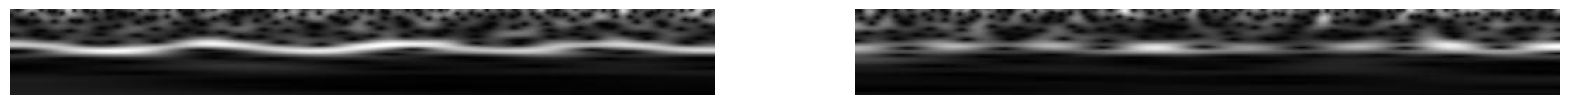

In [38]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
fig, axes = plt.subplots(1, 2, figsize=(20, 10))
for i_f, f in enumerate(files_df['file name']):
    image = mpimg.imread(images_basedir / f)
    axes[i_f].imshow(image)
    axes[i_f].axis('off')

In [39]:
output_file = f'analysis_{"-".join(files)}.jpg'
fig.savefig(output_file, bbox_inches='tight')

In [40]:
# from IPython.display import display, Markdown
# display(Markdown(f"[Open Saved Plot]({output_file})"))

In [41]:
from IPython.display import HTML
download_link = f'<a href="{output_file}" download>Download Saved Plot</a>'
HTML(download_link)

In [42]:
train_df = pd.read_parquet(parameters_filename.with_suffix('.parquet'))
# train_df.plot(y=('train', 'loss'), logy=True, title='Training Loss')
print(train_df.columns)
train_df

MultiIndex([('train',           'loss'),
            ('train', 'log_likelihood'),
            ('train',             'KL'),
            ('valid',           'loss'),
            ('valid', 'log_likelihood'),
            ('valid',             'KL')],
           )


train                                     valid                 \
              loss log_likelihood            KL         loss log_likelihood   
0     5.263407e+06  -5.252146e+06  11260.746680  5731.315386   -5713.033843   
1     2.220971e+06  -2.215758e+06   5213.066675  4558.033287   -4545.509891   
2     2.001894e+06  -1.996676e+06   5218.362113  4377.781611   -4367.748719   
3     1.949016e+06  -1.945007e+06   4009.270046  4304.290553   -4296.050684   
4     1.923711e+06  -1.920293e+06   3418.557996  4251.083263   -4243.135584   
...            ...            ...           ...          ...            ...   
4995 -4.493344e+05   4.577826e+05   8448.190651  -718.941410     737.741113   
4996 -4.493111e+05   4.577688e+05   8457.633696  -724.834956     743.550653   
4997 -4.492175e+05   4.576564e+05   8438.941839  -728.834212     747.520473   
4998 -4.491836e+05   4.576253e+05   8441.729927  -728.250990     747.035365   
4999 -4.492446e+05   4.576902e+05   8445.601343  -722.821855     741.569960   

                 
             KL  
0     18.281553  
1     12.523397  
2     10.032901  
3      8.239877  
4      7.947688  
...         ...  
4995  18.799705  
4996  18.715698  
4997  18.686260  
4998  18.784372  
4999  18.748107  

[5000 rows x 6 columns]

Hierarchical columns are flattened (since, apparently, `altair` doesn't support the former).

In [44]:
train_df.columns = train_df.columns.to_flat_index().str.join('_')
train_df.columns

Index(['train_loss', 'train_log_likelihood', 'train_KL', 'valid_loss',
       'valid_log_likelihood', 'valid_KL'],
      dtype='object')

In [68]:
log_likelihood_chart = alt.Chart(train_df.iloc[:].reset_index()).mark_line().encode(
    x='index:Q',
    y='train_log_likelihood:Q',
    # y=alt.Y('value:Q', scale=alt.Scale(type='log')),
).properties(
    width=600, height=600
)

kl_chart = alt.Chart(train_df.iloc[:].reset_index()).mark_line().encode(
    x='index:Q',
    y='train_KL:Q',
    # y=alt.Y('value:Q', scale=alt.Scale(type='log')),
).properties(
    width=600, height=600
)

log_likelihood_chart | kl_chart

alt.HConcatChart(...)